# 1.1. The Simplest Graph
##Let's build a simple graph with 3 nodes and one conditional edge. 

![Screenshot 2024-08-20 at 3.11.22 PM.png](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dba5f465f6e9a2482ad935_simple-graph1.png)

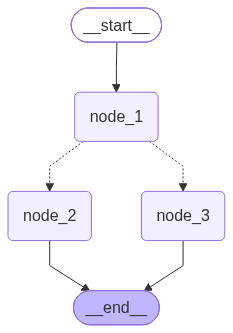

Invocation - 1 
---Node 1---
---Node 3---
Invocation - 2 
---Node 1---
---Node 2---


{'graph_state': 'Hi, this is Lance. I am happy!'}

In [9]:
from dotenv import load_dotenv
from typing_extensions import TypedDict
import random
from typing import Literal
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

# Define Nodes
class State(TypedDict):
    graph_state: str

def node_1(state):
    print("---Node 1---")
    return {"graph_state": state['graph_state'] +" I am"}

def node_2(state):
    print("---Node 2---")
    return {"graph_state": state['graph_state'] +" happy!"}

def node_3(state):
    print("---Node 3---")
    return {"graph_state": state['graph_state'] +" sad!"}

# Define Conditional Edge
def decide_mood(state) -> Literal["node_2", "node_3"]:
    
    # Often, we will use state to decide on the next node to visit
    user_input = state['graph_state'] 
    
    # Here, let's just do a 50 / 50 split between nodes 2, 3
    if random.random() < 0.5:

        # 50% of the time, we return Node 2
        return "node_2"
    
    # 50% of the time, we return Node 3
    return "node_3"

# Build graph
builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

# Logic
builder.add_edge(START, "node_1")
builder.add_conditional_edges("node_1", decide_mood)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

# Invokation - 1 
print("Invocation - 1 ")
graph.invoke({"graph_state" : "Hi, this is Lance."})

# Invokation - 2 
print("Invocation - 2 ")
graph.invoke({"graph_state" : "Hi, this is Lance."})

# 1.2. Chain
####    Concepts - 
 1. Chat **Messages** as our graph state, 
 2. Chat Models in graph nodes, 
 3. Binding Tools to out chat models, 
 4. Executing tools Call in graph nodes 
 
![Screenshot 2024-08-21 at 9.24.03 AM.png](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbab08dd607b08df5e1101_chain1.png)

Result: content="The best place to see orcas in the United States is the Pacific Northwest, particularly around the San Juan Islands in Washington State. This area is known for its resident orca pods, primarily from mid-April to early October, with peak sightings occurring in July and August. The nutrient-rich waters and ample supply of salmon attract orcas and make it an ideal location for whale watching.\n\nThere are several tour operators based in Friday Harbor on San Juan Island and in Anacortes on the mainland that offer guided whale-watching tours. Additionally, the Lime Kiln Point State Park on San Juan Island is known as one of the best land-based spots to see orcas, as they often pass very close to the shore.\n\nAnother excellent location is the waters around the Puget Sound and the Strait of Juan de Fuca, where transient orcas can often be spotted. If you're interested in seeing these magnificent creatures in the wild, planning a trip to this region will maximize your chances

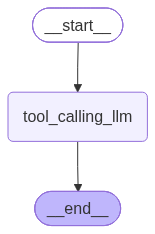

Case 1: LLM responds without any tool calls
================================ Human Message =================================

Hello!
================================== Ai Message ==================================

Hi there! How can I assist you today?


Case 2: LLM responds with a tool call
================================ Human Message =================================

Multiply 2 and 3
================================== Ai Message ==================================
Tool Calls:
  multiply (call_Gc8SGCDUth0mA9dIgJfipl45)
 Call ID: call_Gc8SGCDUth0mA9dIgJfipl45
  Args:
    a: 2
    b: 3


In [1]:
import os
from dotenv import load_dotenv
from pprint import pprint

# Load environment variables (OPENAI_API_KEY, LangSmith settings, etc.)
load_dotenv()

# LangChain message types and graph primitives
from langchain_core.messages import AIMessage, HumanMessage, AnyMessage
from langgraph.graph.message import add_messages
from langgraph.graph import MessagesState

from typing_extensions import TypedDict
from typing import Annotated

# Graph Construction Imports
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END


# ==========================================
# 1. CHAT MESSAGES (CONVERSATION HISTORY)
# ==========================================
# Memory Note: Messages in LangChain are structured objects (HumanMessage, AIMessage, etc.)
# rather than plain strings, allowing you to attach metadata like speaker names.
messages = [AIMessage(content=f"So you said you were researching ocean mammals?", name="Model")]
messages.append(HumanMessage(content=f"Yes, that's right.", name="Lance"))
messages.append(AIMessage(content=f"Great, what would you like to learn about.", name="Model"))
messages.append(HumanMessage(content=f"I want to learn about the best place to see Orcas in the US.", name="Lance"))


# ==========================================
# 2. CHAT MODEL INVOCATION & METADATA
# ==========================================
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o")

# Pass the entire conversation history list to invoke the model
result = llm.invoke(messages)

print(f"Result: {result}, Type: {type(result)}")
print(f"Result content: {result.content}")
# Response metadata contains token usage, finish reason, model version, etc.
pprint(f"Result Metadata: {result.response_metadata}")


# ==========================================
# 3. TOOLS (FUNCTION CALLING) BINDINGS
# ==========================================
def multiply(a: int, b: int) -> int:
    return a * b

def add(a: int, b: int) -> int:
    return a + b

# bind_tools converts standard Python functions into JSON schemas 
# that the LLM understands and can choose to invoke.
llm_with_tools = llm.bind_tools([multiply, add])

# Test LLM tool-calling behavior directly
tool_call = llm_with_tools.invoke([HumanMessage(content=f"Please multiply 5 and 6.", name="Pushpam")])
print(f"Tool Call 1: {tool_call.tool_calls}")


# ==========================================
# 4 & 5. CUSTOM STATE & REDUCER FUNCTIONS
# ==========================================
# Memory Note: State in LangGraph dictates what data flows between nodes.
# By default, node returns overwrite state keys. 
# Using `Annotated` with `add_messages` turns the list into an append-only log 
# (meaning new messages are appended to history instead of replacing it).
class MessagesState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

# Demonstrating how `add_messages` handles combining state updates:
initial_messages = [
    AIMessage(content="Hello! How can I assist you?", name="Model"),
    HumanMessage(content="I'm looking for information on marine biology.", name="Pushpam")
]
new_message = AIMessage(content="Sure, I can help with that. What specifically are you interested in?", name="Model")

# This appends `new_message` to `initial_messages` under the hood
add_messages(initial_messages, new_message)


# ==========================================
# 6. DEFINE GRAPH NODES & BUILD GRAPH
# ==========================================
# The node function receives the current graph state and returns an update.
def tool_calling_llm(state: MessagesState):
    # Invokes the tool-bound LLM using the current accumulated message history
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

# Initialize StateGraph with our custom MessagesState schema
builder = StateGraph(MessagesState)

# Add our single node
builder.add_node("tool_calling_llm", tool_calling_llm)

# Define simple linear control flow: START -> Node -> END
builder.add_edge(START, "tool_calling_llm")
builder.add_edge("tool_calling_llm", END)

# Compile the graph into an executable runnable app
graph = builder.compile()

# Visualize graph structure
display(Image(graph.get_graph().draw_mermaid_png()))


# ==========================================
# 7. EXECUTION TEST CASES
# ==========================================

# Case 1: Standard text query (No tool needed)
print("Case 1: LLM responds without any tool calls")
messages = graph.invoke({"messages": HumanMessage(content="Hello!")})
for m in messages['messages']:
    m.pretty_print()

# Case 2: Math query (Triggers structured tool call generation)
print("\n\nCase 2: LLM responds with a tool call")
messages = graph.invoke({"messages": HumanMessage(content="Multiply 2 and 3")})
for m in messages['messages']:
    m.pretty_print()

# 1.3. Agent
####    Concepts - 
 1. [Generic Agent Architecture](https://www.langchain.com/blog/planning-for-agents)
 2. [ReAct  ( Act, Observe, Reason)](https://arxiv.org/html/2210.03629v3#A2)
 3. [Observability (through Langssmith)](https://docs.langchain.com/langsmith/observability-concepts)

 ![Screenshot 2024-08-21 at 12.44.33 PM.png](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbac0ba0bd34b541c448cc_agent1.png)

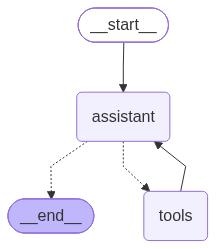

================================ Human Message =================================

Add 3 and 4. Multiply the output by 2. Divide the output by 5
================================== Ai Message ==================================
Tool Calls:
  add (call_PQ3Qr7Sq1JcFehOvfkUHQPnO)
 Call ID: call_PQ3Qr7Sq1JcFehOvfkUHQPnO
  Args:
    a: 3
    b: 4
================================= Tool Message =================================
Name: add

7
================================== Ai Message ==================================
Tool Calls:
  multiply (call_qSc0JGcn8nNz2lew2u5ogWAk)
 Call ID: call_qSc0JGcn8nNz2lew2u5ogWAk
  Args:
    a: 7
    b: 2
================================= Tool Message =================================
Name: multiply

14
================================== Ai Message ==================================
Tool Calls:
  divide (call_hi0MGJNLbad7EGb6o5F99biy)
 Call ID: call_hi0MGJNLbad7EGb6o5F99biy
  Args:
    a: 14
    b: 5
================================= Tool Message ===============

In [3]:
import os
from dotenv import load_dotenv

# Load environment variables from .env file (e.g., OPENAI_API_KEY, LANGSMITH_API_KEY)
load_dotenv()

from langchain_openai import ChatOpenAI
from langgraph.graph import MessagesState
from langchain_core.messages import HumanMessage, SystemMessage

# Graph Core Imports
from langgraph.graph import START, StateGraph
from langgraph.prebuilt import tools_condition, ToolNode
from IPython.display import Image, display

# ==========================================
# 1. DEFINE TOOLS
# ==========================================
# Standard Python functions equipped with docstrings and type hints. 
# LangChain uses the docstrings and signatures to tell the LLM how and when to use them.

def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b


def add(a: int, b: int) -> int:
    """Adds a and b.

    Args:
        a: first int
        b: second int
    """
    return a + b

def divide(a: int, b: int) -> float:
    """Divide a and b.

    Args:
        a: first int
        b: second int
    """
    return a / b

# ==========================================
# 2. INITIALIZE LLM & BIND TOOLS
# ==========================================
tools = [add, multiply, divide]
llm = ChatOpenAI(model="gpt-4o")

# bind_tools equips the OpenAI model with function-calling schemas for our tools.
# parallel_tool_calls=False ensures sequential execution (vital for multi-step math problems).
llm_with_tools = llm.bind_tools(tools, parallel_tool_calls=False)


# ==========================================
# 3. DEFINE SYSTEM MESSAGE & AGENT NODE
# ==========================================
sys_msg = SystemMessage(content="You are a helpful assistant tasked with performing arithmetic on a set of inputs.")

def assistant(state: MessagesState):
    """
    The Assistant Node:
    Takes the current conversation state, prepends the system message, 
    and invokes the LLM with bound tools. Returns the new AI message containing 
    either a text response or tool calls.
    """
    return {"messages": [llm_with_tools.invoke([sys_msg] + state["messages"])]}


# ==========================================
# 4. BUILD THE STATE GRAPH (ReAct Architecture)
# ==========================================
# MessagesState automatically manages a list of messages under the hood.
builder = StateGraph(MessagesState)

# Add nodes to the graph
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools)) # ToolNode executes the requested tool functions automatically

# Define Control Flow Edges
builder.add_edge(START, "assistant") # Entry point: execution always starts at the assistant node

builder.add_conditional_edges(
    "assistant",
    # tools_condition is a pre-built router:
    # - If assistant output contains tool_calls -> routes to "tools" node.
    # - If assistant output contains no tool calls (final answer) -> routes to END automatically.
    tools_condition,
)

builder.add_edge("tools", "assistant") # Loop back: after tools execute, return control back to the assistant node


# ==========================================
# 5. COMPILE AND VISUALIZE
# ==========================================
react_graph = builder.compile()

# Render the graph structure visually (requires graphviz installed in environment)
display(Image(react_graph.get_graph(xray=True).draw_mermaid_png()))


# ==========================================
# 6. EXECUTE THE GRAPH
# ==========================================
# Test with a multi-step query requiring sequential tool execution.
messages = [HumanMessage(content="Add 3 and 4. Multiply the output by 2. Divide the output by 5")]
messages = react_graph.invoke({"messages": messages})

# Print out each message trace cleanly in order
for m in messages['messages']:
    m.pretty_print()